# 01. HDFS 데이터 점검 (EDA) · Drain 검증

- 작성: 옥상민 / 2026-10-12 / 4~6주차 계획 1단계 (`docs/plan_week4-6.md`)
- 목적: 모델 설계 전에 데이터 특성을 확인하고, Drain 파싱이 공식 정답과 일치하는지 검증한다.
- 실행 전 `make data` 와 `python -m logguard.data.drain_tuning` 이 끝나 있어야 한다.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from logguard.config import load_config

cfg = load_config()
P, I, R = cfg["paths"]["processed_dir"], cfg["paths"]["interim_dir"], cfg["paths"]["results_dir"]
sessions = pd.read_parquet(I / "hdfs_sessions.parquet")
templates = pd.read_csv(I / "hdfs_templates.csv")
train, val, test = (pd.read_parquet(P / f"{n}.parquet") for n in ("train", "val", "test"))
vocab = json.loads((P / "event_vocab.json").read_text())
known = {int(k) for k in vocab["event_to_index"]}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. 데이터 개요

In [2]:
summary = json.loads((I / "parse_summary.json").read_text())
split = json.loads((P / "split_summary.json").read_text())
print({k: summary[k] for k in ("lines", "templates", "sessions", "anomaly_sessions", "anomaly_ratio")})
pd.DataFrame(split["splits"]).T[["sessions", "normal", "anomaly", "anomaly_ratio", "anomaly_dropped"]]

{'lines': 11175629, 'templates': 52, 'sessions': 575061, 'anomaly_sessions': 16838, 'anomaly_ratio': 0.02928}


,sessions,normal,anomaly,anomaly_ratio,anomaly_dropped
train,334933.0,334933.0,0.0,0.00000,10102.0
val,115011.0,111644.0,3367.0,0.02928,0.0
test,115015.0,111646.0,3369.0,0.02929,0.0


## 2. Drain 파싱 검증 · 튜닝

정답은 Loghub 공식 템플릿 29개. 지표는 Grouping Accuracy(GA)와, 서로 다른 정답 이벤트가 한 템플릿으로 합쳐진 라인 수(merged_lines).
합쳐짐은 이상 신호를 정상 이벤트에 묻어버리므로 이상 탐지에 가장 해롭다.

In [3]:
grid = pd.read_csv(R / "drain_tuning.csv")
validation = json.loads((R / "drain_validation.json").read_text())
print(f"현재 설정 블록 시퀀스 일치율: {validation['block_match_rate']:.2%} ({validation['blocks_exact_match']:,}/{validation['blocks_compared']:,})")
grid.pivot(index="sim_th", columns="depth", values="grouping_accuracy").round(4)

현재 설정 블록 시퀀스 일치율: 100.00% (575,061/575,061)


depth,3,4,5,6
sim_th,,,,
0.30,0.7195,0.8457,0.8457,0.8457
0.40,0.7196,0.8457,0.8457,0.8457
0.50,0.8457,0.8457,0.8457,0.8457
0.60,0.8457,0.8457,0.8457,0.8457
0.70,0.8457,0.8457,0.8457,0.8457
0.80,0.8457,0.8457,0.8457,0.8457
0.85,0.9984,0.9984,0.9984,0.9984
0.90,0.9984,0.9984,0.9984,0.9984
0.95,0.9984,0.9984,0.9984,0.9984


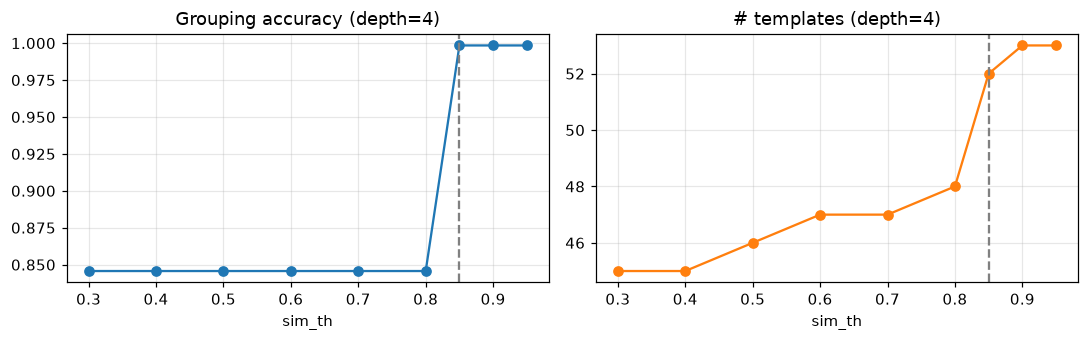

In [4]:
g4 = grid[grid["depth"] == 4].sort_values("sim_th")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(g4["sim_th"], g4["grouping_accuracy"], "o-"); ax[0].set(title="Grouping accuracy (depth=4)", xlabel="sim_th")
ax[1].plot(g4["sim_th"], g4["templates"], "o-", color="C1"); ax[1].set(title="# templates (depth=4)", xlabel="sim_th")
for a in ax: a.axvline(0.85, ls="--", c="gray")
plt.tight_layout()

In [5]:
templates[templates["template"].str.contains("PacketResponder <:NUM:> for block")][["event_id", "template", "occurrences"]]

,event_id,template,occurrences
2,3,PacketResponder <:NUM:> for block <:BLK:> term...,1706679
25,26,PacketResponder <:NUM:> for block <:BLK:> Inte...,49


**결론**
- sim_th ≤ 0.8 에서는 `PacketResponder .. terminating`(정상, 170만 줄)과 `.. Interrupted.`(49줄, 50개 세션 **전부 이상**)이 한 템플릿으로 합쳐졌다.
- **sim_th = 0.85** 로 변경 → 합쳐짐 0건, GA 0.846 → 0.998, 공식 Event_traces 와 **블록 시퀀스 100% 일치**. depth 는 영향 없음(4 유지).
- 남은 GA 손실은 공식 이벤트 하나가 예외 종류별로 더 잘게 쪼개진 경우(split)라 탐지에는 오히려 정보가 늘어난다.

## 3. 세션 길이

          count  mean   std   min   25%   50%   75%    max
label                                                     
0      558223.0  19.5   4.8  13.0  19.0  19.0  20.0  298.0
1       16838.0  17.1  12.4   2.0   4.0  20.0  26.0  284.0


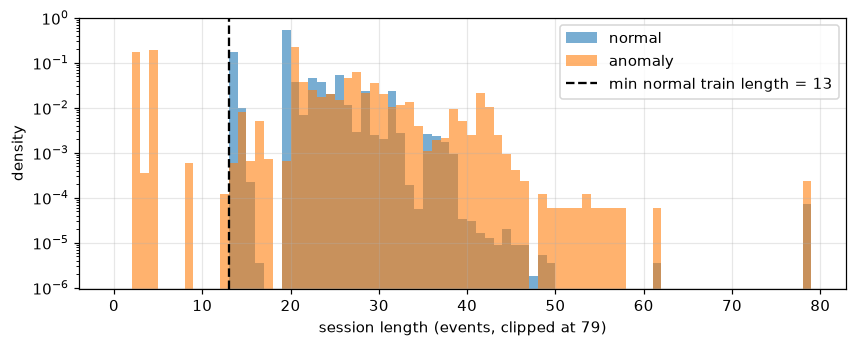

In [6]:
print(sessions.groupby("label")["length"].describe().round(1))
fig, ax = plt.subplots(figsize=(9, 3.2))
bins = np.arange(0, 80)
for lab, name in [(0, "normal"), (1, "anomaly")]:
    ax.hist(sessions.loc[sessions.label == lab, "length"].clip(upper=79), bins=bins, alpha=0.6, density=True, label=name)
ax.axvline(train["length"].min(), ls="--", c="k", label=f"min normal train length = {train['length'].min()}")
ax.set(xlabel="session length (events, clipped at 79)", ylabel="density", yscale="log"); ax.legend()

**결론:** 정상 세션은 최소 13개 이벤트인데, 이상 세션의 약 37%는 13개 미만으로 **중간에 끊긴 세션**이다.
→ Rule-Based 의 길이 규칙을 '너무 긴 세션'뿐 아니라 '너무 짧은 세션'도 잡도록 수정 (test F1 0.148 → 0.573).

## 4. 이벤트별 분포 (정상 vs 이상)

In [7]:
def share(df):
    c = Counter(e for seq in df["events"] for e in set(seq.tolist()))
    return pd.Series({k: v / len(df) for k, v in c.items()})

ev = pd.DataFrame({"normal": share(sessions[sessions.label == 0]), "anomaly": share(sessions[sessions.label == 1])}).fillna(0)
ev = ev.join(templates.set_index("event_id")[["template", "occurrences"]])
ev["in_train_vocab"] = ev.index.isin(list(known))
ev.sort_values("anomaly", ascending=False).round(4).head(25)

,normal,anomaly,template,occurrences,in_train_vocab
1,1.0000,1.0000,Receiving block <:BLK:> src: <:IP:> dest: <:IP:>,1723232,True
2,1.0000,1.0000,BLOCK* NameSystem.allocateBlock: <:PATH:> <:BLK:>,575061,True
3,1.0000,0.6329,PacketResponder <:NUM:> for block <:BLK:> term...,1706679,True
5,1.0000,0.6314,BLOCK* NameSystem.addStoredBlock: blockMap upd...,1719741,True
4,1.0000,0.6314,Received block <:BLK:> of size <:NUM:> from <:...,1706514,True
17,0.8173,0.6172,Deleting block <:BLK:> file <:PATH:>,1402047,True
34,0.8145,0.6139,BLOCK* NameSystem.delete: <:BLK:> is added to ...,1396174,True
35,0.0004,0.3044,Unexpected error trying to delete block <:BLK:...,5545,True
10,0.2397,0.2154,<:IP:> Served block <:BLK:> to <:IP:>,428726,True
6,0.0032,0.2058,Received block <:BLK:> src: <:IP:> dest: <:IP:...,7097,True


In [8]:
only_anom = ev[(ev["normal"] == 0) & (ev["anomaly"] > 0)]
print(f"정상 세션에 한 번도 안 나오고 이상 세션에만 나오는 이벤트: {len(only_anom)}종")
only_anom.sort_values("anomaly", ascending=False)[["anomaly", "template"]].round(4)

정상 세션에 한 번도 안 나오고 이상 세션에만 나오는 이벤트: 33종


,anomaly,template
16,0.1916,writeBlock <:BLK:> received exception java.io....
18,0.0290,Receiving empty packet for block <:BLK:>
19,0.0032,Exception in receiveBlock for block <:BLK:> ja...
20,0.0032,writeBlock <:BLK:> received exception java.io....
45,0.0027,PendingReplicationMonitor timed out block <:BLK:>
26,0.0027,PacketResponder <:NUM:> for block <:BLK:> Inte...
24,0.0023,Exception in receiveBlock for block <:BLK:> <:*:>
27,0.0023,Changing block file offset of block <:BLK:> fr...
25,0.0021,writeBlock <:BLK:> received exception java.io....
28,0.0015,<:IP:>:Exception writing block <:BLK:> to mirr...


## 5. 학습 때 못 본 이벤트(UNK)와 짧은 세션 — 각각 몇 %의 이상을 설명하나

In [9]:
min_len = train["length"].min()
rows = []
for name, d in [("val", val), ("test", test)]:
    a = d["label"] == 1
    unk = d["events"].apply(lambda x: not set(x.tolist()) <= known)
    short = d["length"] < min_len
    rows.append({"split": name, "anomaly": int(a.sum()),
                 "UNK_recall": (unk & a).sum() / a.sum(), "UNK_false_pos": int((unk & ~a).sum()),
                 "short_recall": (short & a).sum() / a.sum(), "short_false_pos": int((short & ~a).sum()),
                 "UNK_or_short_recall": ((unk | short) & a).sum() / a.sum()})
pd.DataFrame(rows).round(3)

,split,anomaly,UNK_recall,UNK_false_pos,short_recall,short_false_pos,UNK_or_short_recall
0,val,3367,0.226,0,0.363,0,0.397
1,test,3369,0.229,0,0.366,0,0.400


In [10]:
# 짧은 이상 세션 중 '정상 시퀀스의 앞부분과 똑같은' 것 = 다음 이벤트만 보는 DeepLog 가 구조적으로 못 잡는 유형
prefixes = set()
for seq in train["events"]:
    t = tuple(seq.tolist())
    prefixes.update(t[:k] for k in range(1, len(t) + 1))
short_anom = test[(test.label == 1) & (test.length < min_len)]
is_prefix = short_anom["events"].apply(lambda x: tuple(x.tolist()) in prefixes)
print(f"test 짧은 이상 세션 {len(short_anom)}개 중 정상 시퀀스의 앞부분과 동일: {is_prefix.sum()}개 "
      f"(test 전체 이상의 {is_prefix.sum() / test.label.sum():.1%})")
Counter(tuple(x.tolist()) for x in short_anom["events"]).most_common(5)

test 짧은 이상 세션 1232개 중 정상 시퀀스의 앞부분과 동일: 577개 (test 전체 이상의 17.1%)


[((1, 2), 338),
 ((2, 1, 1, 16), 278),
 ((1, 1, 2, 16), 242),
 ((2, 1), 239),
 ((1, 2, 1, 16), 133)]

**결론**
- UNK 이벤트만으로 이상의 약 23%를 **오탐 0건**으로 잡는다 → 모델 판정 전에 'UNK 즉시 이상' 규칙을 둔다.
- 이상의 약 17%는 정상 시퀀스의 앞부분에서 끊긴 세션이라, '다음 이벤트'만 예측하는 기본 DeepLog 로는 **원리적으로 탐지 불가** (Recall 상한 약 83%).
  → DeepLog 학습 시퀀스 끝에 **종료 토큰(EOS)** 을 붙여 '여기서 끝나면 안 된다'를 학습시킨다.

## 6. 슬라이딩 윈도우 중복률 (DeepLog 학습 데이터 크기)

In [11]:
rows = []
for w in (10, 15, 20):
    pairs, wins, total = set(), set(), 0
    for seq in train["events"]:
        q = (0,) * w + tuple(seq.tolist())
        for i in range(w, len(q)):
            pairs.add(q[i - w:i + 1]); wins.add(q[i - w:i]); total += 1
    rows.append({"window": w, "total_windows": total, "unique_(window,next)": len(pairs), "unique_windows": len(wins),
                 "compression": round(total / len(pairs), 1)})
pd.DataFrame(rows)

,window,total_windows,"unique_(window,next)",unique_windows,compression
0,10,6532627,29103,22699,224.5
1,15,6532627,62125,52745,105.2
2,20,6532627,86933,76770,75.1


**결론:** 정상 학습 윈도우 653만 개가 고유 (윈도우, 다음 이벤트) 쌍 기준 w=10 에서 약 2.9만 개로 줄어든다(약 224배).
고유 쌍 + 빈도 가중치로 학습하면 M2 로컬에서도 충분하다 (Colab 불필요 예상).

## 7. 모델 설계 반영 사항 (2단계 이후)

| # | 발견 | 반영 |
|---|---|---|
| 1 | Drain sim_th 0.5 에서 이상 이벤트(Interrupted)가 정상 이벤트에 합쳐짐 | sim_th 0.85 적용, 공식 정답과 100% 일치 확인 |
| 2 | 이상의 약 37% 가 정상 최소 길이(13)보다 짧은 세션 | Rule-Based 길이 규칙 양방향화 (F1 0.573) |
| 3 | UNK 이벤트가 이상의 약 23% 를 오탐 0건으로 설명 | 모델 앞단에 'UNK 즉시 이상' 규칙 |
| 4 | 이상의 약 17% 는 정상 시퀀스 앞부분에서 끊김 → 기본 DeepLog 탐지 불가 | DeepLog 에 EOS 토큰 추가 |
| 5 | 윈도우 중복이 매우 큼 (224배) | 고유 윈도우 + 빈도 가중치 학습 |